# IT Incident Resolution Time Prediction

Can we predict how long an IT incident will take to resolve using only the information available when it is opened?

**Contents**

1. Introduction and Business Problem
2. Dataset Overview
3. Data Exploration and Quality
4. Target Definition and Incident Reconstruction
5. Feature Engineering
6. Data Splitting and Leakage Prevention
7. Baseline and Regression Models
8. Model Tuning and Selection
9. Final Evaluation
10. Model Interpretation
11. Limitations and Future Work
12. Conclusion
13. References

## 1. Introduction and Business Problem

IT support teams handle incidents every day. Some are solved quickly, while others take several weeks. Predicting resolution time at the moment an incident is opened could help teams plan their work and inform users.

The dataset is a ServiceNow event log, not a simple table of incidents. Each incident can have several rows, and some information is only available after resolution. Using such information would cause **data leakage** and make the model unrealistic.

**Main questions:**
- Can we predict resolution time using information available at opening?
- Which models give the best results?
- Which features are most useful?
- How well does the model handle short and long incidents?
- What are its main limitations?

**Approach:** I clean and analyse the data, rebuild one row per incident, select valid features, split the data by date, compare three models (Ridge, Random Forest and HistGradientBoosting), tune them and evaluate the final model on the test set.

**Main results:**
- The final model improves MAE by 11.5% compared to the baseline (117.2 h vs 132.5 h).
- It works better on short incidents. Long incidents account for about 91% of the total error.
- The main features are `assignment_group` and `sys_created_by`. Priority and urgency have little impact.

### Setup

In [1]:
import glob
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 90)
RS = 42    # random seed used everywhere
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

# raw file, relative to the notebooks folder (or to the project root)
found = glob.glob("../data/raw/incident_event_log.csv") + glob.glob("data/raw/incident_event_log.csv")
assert found, "incident_event_log.csv not found in data/raw"
RAW_FILE = found[0]


def regression_metrics(y_true, y_pred):
    """MAE, RMSE and RMSLE in hours. Negative predictions are set to 0 (a duration can't be negative)."""
    y_pred = np.clip(y_pred, 0, None)
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "RMSLE": np.sqrt(np.mean((np.log1p(y_true) - np.log1p(y_pred)) ** 2))}

pandas 2.3.3 | numpy 2.2.6 | scikit-learn 1.7.2


## 2. Dataset Overview

The dataset comes from the UCI repository: *Incident management process enriched event log*. It contains anonymised ServiceNow data. The documentation reports 141,712 events, 24,918 incidents and 36 attributes. I check these numbers during loading.

The data is stored in a CSV file. Missing values are marked with `?`, and dates use the day/month/year format. I use an explicit date format to avoid parsing errors.

In [2]:
ID = "number"
DATE_COLS = ["opened_at", "sys_created_at", "sys_updated_at", "resolved_at", "closed_at"]
BOOL_COLS = ["active", "made_sla", "knowledge", "u_priority_confirmation"]
INT_COLS = ["reassignment_count", "reopen_count", "sys_mod_count"]

df = pd.read_csv(RAW_FILE, dtype=str, na_values=["?"], keep_default_na=False)
for c in DATE_COLS:
    df[c] = pd.to_datetime(df[c], format="%d/%m/%Y %H:%M")
for c in BOOL_COLS:
    b = df[c].str.strip().str.lower().map({"true": True, "false": False})
    assert b.notna().all()
    df[c] = b.astype(bool)
for c in INT_COLS:
    df[c] = pd.to_numeric(df[c]).astype("int64")

n_incidents = df[ID].nunique()
print("rows:", len(df), "| columns:", df.shape[1], "| incidents:", n_incidents)
assert (len(df), n_incidents) == (141712, 24918)    # numbers of the documentation

events = df.groupby(ID, sort=False).size()
display(events.describe().round(1).to_frame("events per incident").T)
print("\ncolumn types:", df.dtypes.astype(str).value_counts().to_dict())
df.head(6)[[ID, "incident_state", "opened_at", "sys_updated_at", "category", "priority", "assignment_group", "resolved_at", "closed_at"]]

rows: 141712 | columns: 36 | incidents: 24918


,count,mean,std,min,25%,50%,75%,max
events per incident,24918.0,5.7,3.7,2.0,3.0,5.0,7.0,58.0



column types: {'object': 24, 'datetime64[ns]': 5, 'bool': 4, 'int64': 3}


,number,incident_state,opened_at,sys_updated_at,category,priority,assignment_group,resolved_at,closed_at
0,INC0000045,New,2016-02-29 01:16:00,2016-02-29 01:23:00,Category 55,3 - Moderate,Group 56,2016-02-29 11:29:00,2016-03-05 12:00:00
1,INC0000045,Resolved,2016-02-29 01:16:00,2016-02-29 08:53:00,Category 55,3 - Moderate,Group 56,2016-02-29 11:29:00,2016-03-05 12:00:00
2,INC0000045,Resolved,2016-02-29 01:16:00,2016-02-29 11:29:00,Category 55,3 - Moderate,Group 56,2016-02-29 11:29:00,2016-03-05 12:00:00
3,INC0000045,Closed,2016-02-29 01:16:00,2016-03-05 12:00:00,Category 55,3 - Moderate,Group 56,2016-02-29 11:29:00,2016-03-05 12:00:00
4,INC0000047,New,2016-02-29 04:40:00,2016-02-29 04:57:00,Category 40,3 - Moderate,Group 70,2016-03-01 09:52:00,2016-03-06 10:00:00
5,INC0000047,Active,2016-02-29 04:40:00,2016-02-29 05:30:00,Category 40,3 - Moderate,Group 24,2016-03-01 09:52:00,2016-03-06 10:00:00


The numbers match the documentation. **Each row represents an event, not an incident.** An incident has a median of 5 events (from 2 to 58). Most values are repeated across events. Dates such as `resolved_at` and `closed_at` are also repeated, which can cause data leakage.

The dataset has 36 columns: 24 text columns, 5 date columns, 4 booleans and 3 counters.

## 3. Data Quality and EDA

### 3.1 Missing values

In [3]:
missing = (df.isna().mean() * 100).round(1)
missing[missing > 0].sort_values(ascending=False).to_frame("% of events missing").T

,caused_by,vendor,cmdb_ci,rfc,problem_id,sys_created_at,sys_created_by,u_symptom,assigned_to,assignment_group,opened_by,resolved_at,closed_code,resolved_by,subcategory,location,category
% of events missing,100.0,99.8,99.7,99.3,98.4,37.5,37.5,23.3,19.4,10.0,3.4,2.2,0.5,0.2,0.1,0.1,0.1


- `caused_by`, `vendor`, `cmdb_ci`, `rfc` and `problem_id` are missing in over 98% of events, so they are not useful.
- `sys_created_by` and `sys_created_at` have many missing values (37.5% of events).
- `u_symptom` is missing for 23% of incidents, and `resolved_at` for 6.24%.

Missing values are kept for now and handled during preprocessing.

### 3.2 Duplicates and dates

In [4]:
print("exact duplicate rows:", int(df.duplicated().sum()))
print("incidents whose last event is not 'Closed':", int((df.groupby(ID, sort=False)["incident_state"].last() != "Closed").sum()))

rows = []
for early, late in [("opened_at", "resolved_at"), ("opened_at", "closed_at"), ("resolved_at", "closed_at"), ("opened_at", "sys_updated_at")]:
    both = df[early].notna() & df[late].notna()
    rows.append({"check": f"{early} later than {late}", "incidents": df.loc[both & (df[early] > df[late]), ID].nunique()})
pd.DataFrame(rows).set_index("check")

exact duplicate rows: 0
incidents whose last event is not 'Closed': 0


,incidents
check,
opened_at later than resolved_at,0
opened_at later than closed_at,0
resolved_at later than closed_at,0
opened_at later than sys_updated_at,5


There are no duplicate rows, and all incidents end in `Closed`. The dates are consistent, except for 5 incidents with an update before their opening time. I keep them.

### 3.3 What changes inside an incident, and where the leakage is

Before using a column as a feature, I need to know if it is the same on every event of an incident, and if it is known at opening.

In [5]:
cols = ["opened_by", "caller_id", "contact_type", "resolved_at", "closed_at", "impact", "urgency", "priority",
        "category", "subcategory", "u_symptom", "assignment_group", "assigned_to", "made_sla", "reassignment_count", "incident_state"]
changes = (df.groupby(ID, sort=False)[cols].nunique(dropna=False) > 1).mean() * 100
display(changes.round(1).sort_values().to_frame("% of incidents where the value changes"))

# the log is "enriched": final values are copied on every row, even on the first event
first = df.groupby(ID, sort=False).head(1)
print("first events where resolved_at is later than the event itself:", f"{(first['resolved_at'] > first['sys_updated_at']).mean():.1%}")
print("first events where closed_at is later than the event itself:", f"{(first['closed_at'] > first['sys_updated_at']).mean():.1%}")

,% of incidents where the value changes
opened_by,0.0
caller_id,0.0
contact_type,0.0
resolved_at,0.0
closed_at,0.0
urgency,1.2
impact,1.3
priority,1.5
category,4.9
subcategory,7.2


first events where resolved_at is later than the event itself: 91.9%
first events where closed_at is later than the event itself: 100.0%


Three types of columns were found:

- **Constant columns:** `opened_by`, `caller_id`, `contact_type`, `resolved_at` and `closed_at`.
- **Columns that rarely change:** `category`, `subcategory`, `u_symptom`, `impact`, `urgency` and `priority`.
- **Columns that change over time:** `state`, `assigned_to`, `reassignment_count`, `made_sla`, etc.

**Important:** `resolved_at` and `closed_at` are not available when an incident is opened. They contain future information, even in the first row of an incident. Using them could cause data leakage. Each column must therefore be checked before using it.

### 3.4 Exploratory analysis

To look at the target I need one row per incident. The function below builds it. The rules are explained and checked in section 4 (target = last resolution time - opening time, features = value on the first event).

incidents: 24918 | with a target: 24905


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
resolution_hours,24905.0,167.3,517.8,0.0,0.3,16.1,141.1,361.1,673.9,2759.9,8070.2


exactly 0 hours     6.3
under 1 hour       36.3
under 24 hours     54.6
over 7 days        21.5
over 30 days        4.6
skewness: 7.1 | skewness of log(1 + hours): 0.3


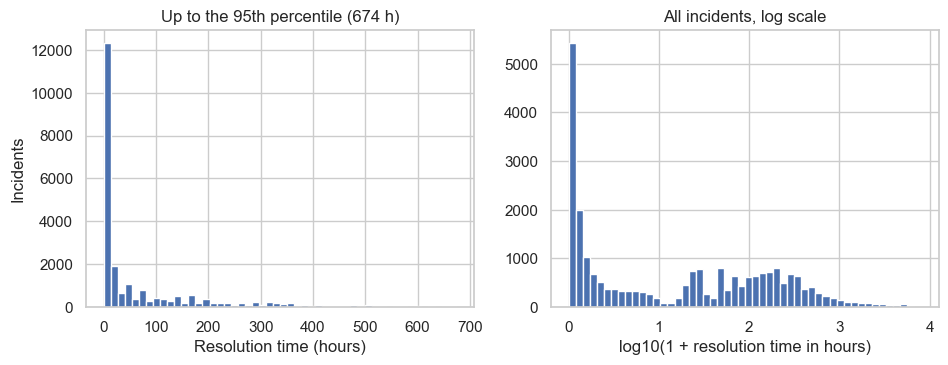

In [6]:
INITIAL_COLS = ["caller_id", "opened_by", "sys_created_by", "contact_type", "location", "category", "subcategory",
                "u_symptom", "impact", "urgency", "priority", "assignment_group", "notify"]
TARGET = "resolution_hours"


def build_incident_table(df):
    """One row per incident: target, features at opening (first event), and columns for analysis only."""
    ev = df.sort_values([ID, "sys_updated_at"], kind="stable")     # ties keep the file order
    g = ev.groupby(ID, sort=False)
    first = g.head(1).set_index(ID)

    # resolution time: resolved_at, or the last event in state Resolved when resolved_at is empty
    resolved_at = g["resolved_at"].max()
    last_resolved_event = ev[ev["incident_state"] == "Resolved"].groupby(ID)["sys_updated_at"].max().reindex(resolved_at.index)
    resolution = resolved_at.fillna(last_resolved_event)

    out = pd.DataFrame({"opened_at": first["opened_at"]})
    out[TARGET] = (resolution - out["opened_at"]).dt.total_seconds() / 3600
    out["target_source"] = np.select([resolved_at.notna(), last_resolved_event.notna()],
                                     ["resolved_at", "last Resolved event"], default="none")
    out[INITIAL_COLS] = first[INITIAL_COLS]
    # analysis only, known after the opening
    out["first_event_state"] = first["incident_state"]
    out["n_events"] = g.size()
    out["reassignment_count"] = g["reassignment_count"].max()
    out["reopen_count"] = g["reopen_count"].max()
    return out.reset_index()


inc = build_incident_table(df)
data = inc[inc[TARGET].notna()].reset_index(drop=True)     # incidents with a target
print("incidents:", len(inc), "| with a target:", len(data))


def by_group(col, d=None):
    """Number of incidents and resolution time (hours) for each value of a column."""
    d = data if d is None else d
    return d.groupby(col, dropna=False, observed=True)[TARGET].agg(
        n="size", median="median", mean="mean", p90=lambda s: s.quantile(0.9)).round(1)


target = data[TARGET]
display(target.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1).to_frame(TARGET).T)
shares = pd.Series({"exactly 0 hours": target.eq(0).mean(), "under 1 hour": target.lt(1).mean(), "under 24 hours": target.lt(24).mean(),
                    "over 7 days": target.gt(168).mean(), "over 30 days": target.gt(720).mean()}) * 100
print(shares.round(1).to_string())
print("skewness:", round(target.skew(), 1), "| skewness of log(1 + hours):", round(np.log1p(target).skew(), 1))

cut = target.quantile(0.95)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(target[target <= cut], bins=50, color="#4C72B0", edgecolor="white")
axes[0].set(title=f"Up to the 95th percentile ({cut:.0f} h)", xlabel="Resolution time (hours)", ylabel="Incidents")
axes[1].hist(np.log10(1 + target), bins=50, color="#4C72B0", edgecolor="white")
axes[1].set(title="All incidents, log scale", xlabel="log10(1 + resolution time in hours)")
plt.show()

**Resolution time:** The target is highly skewed (7.1). The median is 16.1 hours, while the mean is 167.3 hours. Most incidents are resolved quickly (36.3% in less than 1 hour), but 21.5% take more than 7 days. There are also a few very long cases that strongly affect the RMSE. Testing a log transformation of the target could help the model handle these differences.

,n,median,mean,p90
priority,,,,
1 - Critical,185,51.4,189.9,467.0
2 - High,311,49.2,162.8,381.7
3 - Moderate,23677,15.9,164.9,359.7
4 - Low,732,1.0,239.2,387.6


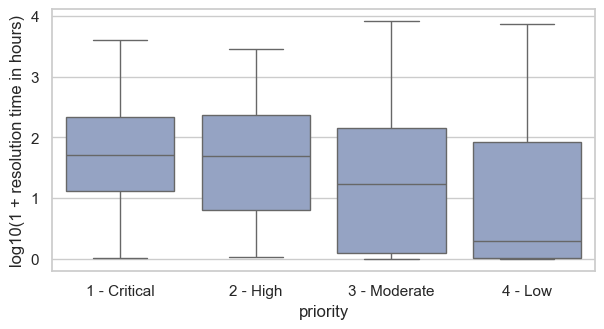

In [7]:
display(by_group("priority"))
order = sorted(data["priority"].unique())
plt.figure(figsize=(7, 3.4))
sns.boxplot(data=data.assign(log_hours=np.log10(1 + target)), x="priority", y="log_hours", order=order, color="#8DA0CB")
plt.ylabel("log10(1 + resolution time in hours)")
plt.show()

**Priority:** Critical and High incidents take longer to resolve than Moderate and Low ones. This may be because more difficult incidents receive higher priority. Since priority depends on impact and urgency, these features may contain similar information.

In [8]:
cat = by_group("category")
cat = cat[cat.index.notna()].sort_values("n", ascending=False)
print("categories:", len(cat), "| the 10 largest cover", round(cat["n"].head(10).sum() / len(data) * 100, 1), "% of the incidents")
display(cat.head(10))
print("assignment_group, 10 largest groups:")
by_group("assignment_group").sort_values("n", ascending=False).head(10)

categories: 56 | the 10 largest cover 74.8 % of the incidents


,n,median,mean,p90
category,,,,
Category 42,3628,0.4,93.4,163.7
Category 26,3267,1.5,73.8,236.9
Category 53,2655,24.4,126.5,330.4
Category 46,2243,48.3,283.7,739.8
Category 32,1495,0.3,52.6,172.1
Category 9,1141,41.4,146.8,363.2
Category 37,1135,19.2,119.4,307.2
Category 23,1071,44.5,156.6,424.9
Category 20,1067,0.9,57.3,188.2


assignment_group, 10 largest groups:


,n,median,mean,p90
assignment_group,,,,
Group 70,12781,0.6,72.0,209.1
Group 20,1367,56.6,210.4,483.5
NaN,905,71.7,151.1,361.1
Group 25,764,78.0,173.5,382.8
Group 24,698,20.1,102.0,213.4
Group 64,622,0.0,14.6,43.1
Group 65,500,40.1,200.3,401.5
Group 55,416,24.9,204.1,476.2
Group 66,389,156.5,414.4,983.5


**Category and group:** The 10 largest categories cover 74.8% of incidents, with very different resolution times. `assignment_group` shows even bigger differences, from 0.6 h for Group 70 to 156.5 h for Group 66. Both features could be useful for the model.

In [9]:
rows = []
for c in ["sys_created_by", "u_symptom", "opened_by", "assignment_group"]:
    miss = data[c].isna()
    rows.append({"column": c, "% missing": round(miss.mean() * 100, 1),
                 "median if missing": round(data.loc[miss, TARGET].median(), 1),
                 "median if present": round(data.loc[~miss, TARGET].median(), 1)})
display(pd.DataFrame(rows).set_index("column"))

print("columns with many values (rare = in fewer than 5 incidents):")
pd.DataFrame({c: {"n_values": data[c].nunique(), "values in < 5 incidents": int((data[c].value_counts() < 5).sum()),
                  "top 10 cover (%)": round(data[c].value_counts().head(10).sum() / len(data) * 100, 1)}
              for c in ["caller_id", "location", "subcategory", "u_symptom", "opened_by", "sys_created_by", "assignment_group"]}).T

,% missing,median if missing,median if present
column,,,
sys_created_by,46.1,0.4,48.5
u_symptom,23.0,20.5,13.0
opened_by,2.9,52.0,13.8
assignment_group,3.6,71.7,13.4


columns with many values (rare = in fewer than 5 incidents):


,n_values,values in < 5 incidents,top 10 cover (%)
caller_id,5242.0,3485.0,4.8
location,218.0,95.0,80.2
subcategory,246.0,90.0,67.6
u_symptom,500.0,307.0,54.7
opened_by,206.0,90.0,64.0
sys_created_by,185.0,85.0,32.0
assignment_group,69.0,8.0,73.3


**Missing values:** When `sys_created_by` is missing, incidents are resolved much faster (0.4 h vs 48.5 h). I will keep this feature but treat missing values carefully. `caller_id` has too many rare values, so I will leave it out. Other columns with many values will need grouping.

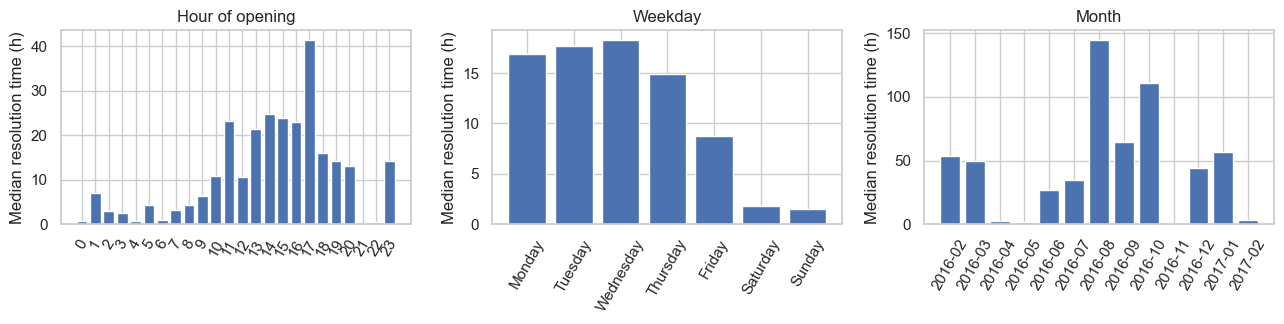

,n,median,mean,p90
opened_at,,,,
2016-02,207,53.4,316.8,666.9
2016-03,8993,49.4,220.2,473.0
2016-04,7933,2.7,137.8,288.6
2016-05,7508,2.0,127.6,291.1
2016-06,5,26.6,1086.0,3224.9
2016-07,14,34.8,279.5,683.3
2016-08,15,145.2,519.9,1568.3
2016-09,12,64.4,433.4,702.5
2016-10,16,111.0,652.4,2302.7


In [10]:
month = data["opened_at"].dt.to_period("M").astype(str)
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
panels = [("Hour of opening", data.groupby(data["opened_at"].dt.hour)[TARGET].median()),
          ("Weekday", data.groupby(data["opened_at"].dt.day_name())[TARGET].median().reindex(days)),
          ("Month", data.groupby(month)[TARGET].median())]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (title, s) in zip(axes, panels):
    ax.bar(s.index.astype(str), s.values, color="#4C72B0")
    ax.set(title=title, ylabel="Median resolution time (h)")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()
by_group(month)

**Opening time:** Weekend incidents are resolved faster than weekday incidents. The opening hour also seems to affect resolution time.

Most incidents (98.9%) were opened between February and May 2016, with large differences between months. The data is limited and changes over time, which may affect the train/test split.

In [11]:
# variables known only after the opening: information only, never used as features
post = ["reassignment_count", "reopen_count", "n_events"]
display(data[post + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).round(2).to_frame("Spearman with target"))
by_group(pd.cut(data["reassignment_count"], [-1, 0, 1, 2, 4, 100], labels=["0", "1", "2", "3-4", "5+"]).rename("reassignments"))

,Spearman with target
reassignment_count,0.56
reopen_count,0.11
n_events,0.77


,n,median,mean,p90
reassignments,,,,
0,13537,0.4,84.2,173.7
1,6237,42.1,173.6,356.2
2,2283,103.0,315.6,608.4
3-4,1929,163.1,389.2,746.5
5+,919,292.1,513.2,985.7


**After opening:** `n_events` and `reassignment_count` are strongly related to resolution time. However, they are only known after opening, so they cannot be used for prediction. Both features will be excluded.

## 4. Target Definition and Incident Reconstruction

The prediction is made when the incident is opened. The target is `resolution_hours`, calculated as the time between `opened_at` and the last `resolved_at` for each incident.

I use the resolution time instead of the closure time because closure usually happens about 120 hours later and does not represent the actual work.

### 4.1 Where does the resolution time come from?

In [12]:
ev = df.sort_values([ID, "sys_updated_at"], kind="stable")
last_resolved = ev[ev["incident_state"] == "Resolved"].groupby(ID)["sys_updated_at"].max()
resolved_at = df.groupby(ID)["resolved_at"].max()
last_resolved = last_resolved.reindex(resolved_at.index)

both = resolved_at.notna() & last_resolved.notna()
print("incidents with resolved_at:", int(resolved_at.notna().sum()), "| without:", int(resolved_at.isna().sum()),
      f"({resolved_at.isna().mean():.2%})")
print("same time in resolved_at and in the last 'Resolved' event:", f"{(resolved_at[both] == last_resolved[both]).mean():.1%}", "of", int(both.sum()))
print("without resolved_at but with a 'Resolved' event:", int((resolved_at.isna() & last_resolved.notna()).sum()))
print("without resolved_at and never 'Resolved':", int((resolved_at.isna() & last_resolved.isna()).sum()))

delay = (df.groupby(ID)["closed_at"].max() - resolved_at).dt.total_seconds() / 3600
print("closed_at - resolved_at (hours), median:", round(delay.median(), 1))
inc["target_source"].value_counts()

incidents with resolved_at: 23362 | without: 1556 (6.24%)
same time in resolved_at and in the last 'Resolved' event: 100.0% of 23362
without resolved_at but with a 'Resolved' event: 1543
without resolved_at and never 'Resolved': 13
closed_at - resolved_at (hours), median: 120.6


target_source
resolved_at            23362
last Resolved event     1543
none                      13
Name: count, dtype: int64

`resolved_at` and the last `Resolved` event give the same time. When `resolved_at` is missing, I use the last `Resolved` event instead. This recovers 1,543 incidents. The remaining 13 have no resolution date, so they are excluded.

These 13 incidents represent only 0.05% of the data, so their impact should be very small.

### 4.2 Special cases: reopened incidents and incidents created already resolved

In [13]:
print("reopened incidents:", int((inc["reopen_count"] > 0).sum()))
print("created already in state 'Resolved':", int((inc["first_event_state"] == "Resolved").sum()))
print("\nresolution time of the incidents created already resolved vs the others:")
display(inc.assign(created_resolved=inc["first_event_state"] == "Resolved")
        .groupby("created_resolved")[TARGET].agg(n="count", median="median", mean="mean").round(1))
print("the 13 incidents without target:")
inc.loc[inc[TARGET].isna(), ["number", "opened_at", "n_events", "first_event_state", "priority"]].head(13)

reopened incidents: 275
created already in state 'Resolved': 1819

resolution time of the incidents created already resolved vs the others:


,n,median,mean
created_resolved,,,
False,23086,22.8,180.3
True,1819,0.0,2.2


the 13 incidents without target:


,number,opened_at,n_events,first_event_state,priority
1935,INC0003115,2016-03-07 09:04:00,2,New,3 - Moderate
3229,INC0005100,2016-03-09 18:35:00,3,New,3 - Moderate
13701,INC0020014,2016-04-16 01:46:00,5,New,3 - Moderate
24904,INC0119241,2017-02-13 06:45:00,2,New,4 - Low
24905,INC0119289,2017-02-13 08:56:00,2,New,4 - Low
24907,INC0119392,2017-02-13 10:33:00,2,New,4 - Low
24908,INC0119457,2017-02-13 11:31:00,2,New,4 - Low
24909,INC0119983,2017-02-14 11:11:00,2,New,4 - Low
24910,INC0119987,2017-02-14 11:15:00,2,New,4 - Low
24911,INC0120268,2017-02-14 18:31:00,2,New,4 - Low


- **275 reopened incidents:** I use the last resolution date to include the reopening time.
- **1,819 incidents already in `Resolved` state:** Their median resolution time is 0 h, compared to 22.8 h for the others. I keep them because they may appear in future predictions and check their impact later.

### 4.3 First or last event?

I use the value from the first event, sorted by `sys_updated_at`. I don't use later values because they may contain information added during the incident.


In [14]:
g = ev.groupby(ID, sort=False)
diff = {c: (g[c].first().fillna("(missing)") != g[c].last().fillna("(missing)")).mean() * 100
        for c in ["assignment_group", "category", "subcategory", "u_symptom", "location", "impact", "urgency", "priority"]}
pd.Series(diff, name="% of incidents where first value != last value").round(1).to_frame()

,% of incidents where first value != last value
assignment_group,33.4
category,4.6
subcategory,6.8
u_symptom,5.2
location,0.2
impact,1.2
urgency,1.1
priority,1.5


`assignment_group` changes in 33.4% of incidents, so the last value is not available at opening. Other features change less often. I therefore use the first event for all features.

**Final dataset:** 24,905 incidents with a target, one row per incident. Features come from the first event, while the last resolution is used for the target.

In [15]:
assert len(inc) == 24918 and len(data) == 24905
data.drop(columns=["target_source", "first_event_state", "n_events", "reassignment_count", "reopen_count"]).head(3)

,number,opened_at,resolution_hours,caller_id,opened_by,sys_created_by,contact_type,location,category,subcategory,u_symptom,impact,urgency,priority,assignment_group,notify
0,INC0000045,2016-02-29 01:16:00,10.216667,Caller 2403,Opened by 8,Created by 6,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,2 - Medium,2 - Medium,3 - Moderate,Group 56,Do Not Notify
1,INC0000047,2016-02-29 04:40:00,29.200000,Caller 2403,Opened by 397,Created by 171,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,2 - Medium,2 - Medium,3 - Moderate,Group 70,Do Not Notify
2,INC0000057,2016-02-29 06:10:00,20.750000,Caller 4416,Opened by 8,NaN,Phone,Location 204,Category 20,Subcategory 125,Symptom 471,2 - Medium,2 - Medium,3 - Moderate,Group 70,Do Not Notify


## 5. Feature Engineering

I use **13 categorical features**, all taken from the first event:

| Group | Features |
|---|---|
| Classification | `priority`, `impact`, `urgency`, `category`, `subcategory`, `u_symptom` |
| Who and where | `assignment_group`, `location`, `contact_type`, `opened_by`, `sys_created_by` |
| Opening time | `hour`, `weekday` |

**Excluded features:**
- `caller_id`: too many rare values.
- `notify`: almost always the same.
- `cmdb_ci`: 99.7% missing.
- `sys_created_at`: too close to `opened_at`.
- `month`: limited data period.
- All features only available after opening.

**Encoding:** I use one-hot encoding. Missing values get their own category, and categories with fewer than 30 training examples are grouped as `rare`. The encoder is fitted only on the training data.

In [16]:
data = data.assign(hour=data["opened_at"].dt.hour.astype(str), weekday=data["opened_at"].dt.dayofweek.astype(str))

FEATURES = ["priority", "impact", "urgency", "category", "subcategory", "u_symptom", "assignment_group",
            "location", "contact_type", "opened_by", "sys_created_by", "hour", "weekday"]
MIN_FREQUENCY = 30
# no feature is the target, the key, a post-opening column or a date of resolution
assert not set(FEATURES) & {TARGET, ID, "target_source", "first_event_state", "n_events", "reassignment_count", "reopen_count", "closed_at", "resolved_at"}


def make_preprocessor(features=FEATURES):
    """One-hot encoding. A missing value is its own level, rare and unseen levels share one column."""
    onehot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_FREQUENCY, sparse_output=False)
    return ColumnTransformer([("cat", onehot, list(features))])


data[FEATURES].nunique().to_frame("distinct values").T

,priority,impact,urgency,category,subcategory,u_symptom,assignment_group,location,contact_type,opened_by,sys_created_by,hour,weekday
distinct values,4,3,3,56,246,500,69,218,4,206,185,24,7


## 6. Validation Strategy and Leakage Prevention

I split incidents by opening date: 60% for training, 20% for validation and 20% for testing. This allows the model to learn from past incidents and predict future ones. A random split could mix different time periods.

**Leakage prevention:**
1. Each incident appears only once.
2. Features come from the first event only.
3. Preprocessing is fitted on the training set only.
4. The test set is kept for the final evaluation.

In [17]:
cut_val, cut_test = data["opened_at"].quantile([0.6, 0.8])
data["split"] = np.select([data["opened_at"] < cut_val, data["opened_at"] < cut_test], ["train", "validation"], default="test")

split_summary = data.groupby("split").agg(n=("opened_at", "size"), first_opened=("opened_at", "min"), last_opened=("opened_at", "max"),
                                          median=(TARGET, "median"), mean=(TARGET, "mean"),
                                          p90=(TARGET, lambda s: s.quantile(0.9))).reindex(["train", "validation", "test"])
span = data.groupby("split")["opened_at"].agg(["min", "max"])
assert span.loc["train", "max"] < span.loc["validation", "min"] and span.loc["validation", "max"] < span.loc["test", "min"]
display(split_summary.round(1))

weekly = data.groupby(data["opened_at"].dt.to_period("W"))[TARGET].agg(n="size", median="median", p90=lambda s: s.quantile(0.9)).round(1)
weekly[weekly["n"] >= 100]

,n,first_opened,last_opened,median,mean,p90
split,,,,,,
train,14943,2016-02-29 01:16:00,2016-04-20 19:57:00,26.6,196.4,406.2
validation,4981,2016-04-20 19:59:00,2016-05-10 22:27:00,1.3,117.0,250.1
test,4981,2016-05-10 22:41:00,2017-02-16 14:17:00,2.6,130.2,311.1


,n,median,p90
opened_at,,,
2016-02-29/2016-03-06,1858,76.4,647.2
2016-03-07/2016-03-13,2071,91.0,525.9
2016-03-14/2016-03-20,1975,49.6,369.2
2016-03-21/2016-03-27,1686,26.6,367.6
2016-03-28/2016-04-03,2174,6.5,291.7
2016-04-04/2016-04-10,2008,8.0,331.3
2016-04-11/2016-04-17,1994,2.5,290.8
2016-04-18/2016-04-24,1401,2.9,358.0
2016-04-25/2016-05-01,2046,0.9,170.0


The three sets follow the time order: train until 2016-04-20, validation until 2016-05-10 and test until 2017-02-16.

Resolution times change during training, dropping from around 76–91 hours in the first weeks to 0.9–8 hours from April. The train median is 26.6 h, compared to 1.3 h for validation and 2.6 h for test.

I keep the date-based split to reflect this change in the data. The reason for the drop is unknown.

In [18]:
train = data[data["split"] == "train"]
val = data[data["split"] == "validation"]
test = data[data["split"] == "test"]
print(len(train), len(val), len(test))

14943 4981 4981


## 7. Baseline and Regression Models

**Metrics:** All errors are measured in hours. Negative predictions are set to 0.

- **MAE:** Average prediction error. Main evaluation metric.
- **RMSE:** Gives more importance to large errors.
- **RMSLE:** Measures errors on a log scale.

**Models:** I first use the training median as a baseline, then compare Ridge, Random Forest and HistGradientBoosting on the validation set.

In [19]:
models = {
    "Baseline (median)": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RS),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RS),
}
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    start = time.time()
    pipe.fit(train[FEATURES], train[TARGET])
    seconds = time.time() - start
    on_val = regression_metrics(val[TARGET], pipe.predict(val[FEATURES]))
    on_train = regression_metrics(train[TARGET], pipe.predict(train[FEATURES]))
    rows.append({"model": name, **on_val, "MAE train": on_train["MAE"], "fit seconds": seconds})
pd.DataFrame(rows).set_index("model").round(2)

,MAE,RMSE,RMSLE,MAE train,fit seconds
model,,,,,
Baseline (median),122.46,433.94,2.59,192.04,0.22
Ridge,162.58,385.05,2.98,192.64,0.23
Random Forest,149.20,382.93,2.72,151.33,28.30
HistGradientBoosting,153.41,380.24,3.01,174.58,4.16


All three models have a higher MAE than the baseline (122.5 h). However, their RMSE is lower. This is because squared-error models are strongly affected by long incidents and tend to overestimate shorter ones.

The train MAE is also higher because the training data contains more long incidents than validation. The difference comes mainly from the data distribution. I will test a log transformation and tune the models next.

## 8. Hyperparameter Optimization

I use random search to find better settings based on validation MAE. I also test a log transformation of the target. For HistGradientBoosting, I compare squared and absolute error losses.

I test 8 Ridge settings, 8 Random Forest settings and 20 HistGradientBoosting settings.

In [20]:
def make_model(name, params):
    """Model with its settings. `log_target` trains on log(1 + hours) and converts back to hours."""
    params = dict(params)
    log_target = params.pop("log_target")
    if name == "Ridge":
        model = Ridge(**params)
    elif name == "Random Forest":
        model = RandomForestRegressor(n_jobs=-1, random_state=RS, **params)
    else:
        model = HistGradientBoostingRegressor(early_stopping=False, random_state=RS, **params)
    if log_target:
        model = TransformedTargetRegressor(model, func=np.log1p, inverse_func=np.expm1)
    return model


def fit_eval(model, features=FEATURES, train_df=train):
    """Fit the pipeline on the train data and score it on validation, in hours."""
    pipe = Pipeline([("prep", make_preprocessor(features)), ("model", model)])
    start = time.time()
    pipe.fit(train_df[features], train_df[TARGET])
    seconds = time.time() - start
    pred = np.clip(pipe.predict(val[features]), 0, None)
    return {**regression_metrics(val[TARGET], pred), "mean error": (pred - val[TARGET]).mean(), "fit seconds": seconds}, pred


SPACES = {
    "Ridge": {"alpha": [0.1, 1, 10, 100], "log_target": [False, True]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None], "min_samples_split": [2, 10, 30],
                      "min_samples_leaf": [1, 5, 20], "log_target": [False, True]},
    "HistGradientBoosting": {"learning_rate": [0.03, 0.05, 0.1], "max_iter": [100, 200, 400], "max_leaf_nodes": [15, 31, 63],
                             "l2_regularization": [0, 1, 10], "loss": ["squared_error", "absolute_error"],
                             "log_target": [False, True]},
}
N_ITER = {"Ridge": 8, "Random Forest": 8, "HistGradientBoosting": 20}

rows = []
for name, space in SPACES.items():
    for params in ParameterSampler(space, N_ITER[name], random_state=RS):
        scores, _ = fit_eval(make_model(name, params))
        rows.append({"model": name, "params": params, **scores})
search = pd.DataFrame(rows)
search["log_target"] = search["params"].map(lambda p: p["log_target"])
search["loss"] = search["params"].map(lambda p: p.get("loss"))
print(len(search), "settings tested")
search.sort_values("MAE").drop(columns=["log_target", "loss"]).head(8).round(2)

36 settings tested


,model,params,MAE,RMSE,RMSLE,mean error,fit seconds
34,HistGradientBoosting,"{'max_leaf_nodes': 31, 'max_iter': 400, 'loss': 'squared_error', 'log_target': True, '...",106.22,399.31,1.80,-81.38,14.45
27,HistGradientBoosting,"{'max_leaf_nodes': 63, 'max_iter': 100, 'loss': 'squared_error', 'log_target': True, '...",106.57,401.23,1.80,-80.92,7.92
16,HistGradientBoosting,"{'max_leaf_nodes': 15, 'max_iter': 400, 'loss': 'squared_error', 'log_target': True, '...",106.88,401.99,1.81,-83.61,8.67
18,HistGradientBoosting,"{'max_leaf_nodes': 63, 'max_iter': 100, 'loss': 'absolute_error', 'log_target': True, ...",107.48,397.95,1.89,-71.05,8.56
11,Random Forest,"{'n_estimators': 200, 'min_samples_split': 30, 'min_samples_leaf': 5, 'max_depth': 20,...",107.72,401.58,1.83,-78.83,20.25
26,HistGradientBoosting,"{'max_leaf_nodes': 63, 'max_iter': 400, 'loss': 'absolute_error', 'log_target': True, ...",107.94,392.21,1.88,-62.54,35.16
8,Random Forest,"{'n_estimators': 200, 'min_samples_split': 30, 'min_samples_leaf': 1, 'max_depth': 20,...",107.97,402.61,1.84,-77.55,21.47
13,Random Forest,"{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 20, 'max_depth': 10,...",108.22,400.92,1.88,-80.12,16.50


In [21]:
# effect of the log target (best MAE of each model), then of the loss for HistGradientBoosting
display(search.groupby(["model", "log_target"])["MAE"].min().unstack().round(1).rename(columns={False: "raw target", True: "log target"}))
hgb = search[search["model"] == "HistGradientBoosting"]
hgb.groupby(["loss", "log_target"])["MAE"].min().unstack().round(1).rename(columns={False: "raw target", True: "log target"})

log_target,raw target,log target
model,,
HistGradientBoosting,109.2,106.2
Random Forest,149.2,107.7
Ridge,162.4,108.3


log_target,raw target,log target
loss,,
absolute_error,109.2,107.5
squared_error,150.6,106.2


**Log transformation:** It improves MAE for all models, especially Ridge and Random Forest. It reduces the influence of long incidents and gives better predictions for shorter ones.

In [22]:
best = search.loc[search.groupby("model")["MAE"].idxmin()].set_index("model")
base_pred = np.full(len(val), train[TARGET].median())
baseline = {**regression_metrics(val[TARGET], base_pred), "mean error": (base_pred - val[TARGET]).mean()}
comparison = pd.concat([pd.DataFrame([baseline], index=["Baseline (median)"]),
                        best[["MAE", "RMSE", "RMSLE", "mean error", "fit seconds"]]]).round(2)
display(comparison)
best["params"]

,MAE,RMSE,RMSLE,mean error,fit seconds
Baseline (median),122.46,433.94,2.59,-90.40,NaN
HistGradientBoosting,106.22,399.31,1.80,-81.38,14.45
Random Forest,107.72,401.58,1.83,-78.83,20.25
Ridge,108.26,399.30,1.88,-80.76,0.23


model
HistGradientBoosting    {'max_leaf_nodes': 31, 'max_iter': 400, 'loss': 'squared_error', 'log_target': True, '...
Random Forest           {'n_estimators': 200, 'min_samples_split': 30, 'min_samples_leaf': 5, 'max_depth': 20,...
Ridge                                                                           {'log_target': True, 'alpha': 10}
Name: params, dtype: object

**Final model: HistGradientBoosting on the log target.** It gives the best validation MAE (106.2 h) and RMSLE (1.80), slightly better than Ridge and Random Forest. I choose it for its overall results, with MAE as the main metric.

In [23]:
top = search.loc[search["MAE"].idxmin()]
name, params = top["model"], top["params"]
print("best setting:", name, params)

# does the result depend on a choice I made? (same model, one change at a time)
variants = {
    "reference": {},
    "train from 28 March": {"train_df": train[train["opened_at"] >= "2016-03-28"]},
    "without sys_created_by": {"features": [f for f in FEATURES if f != "sys_created_by"]},
    "train without created Resolved": {"train_df": train[train["first_event_state"] != "Resolved"]},
}
rows, preds = [], {}
for label, kw in variants.items():
    scores, preds[label] = fit_eval(make_model(name, params), **kw)
    rows.append({"variant": label, "n train": len(kw.get("train_df", train)), **scores})
pd.DataFrame(rows).set_index("variant").round(2)

best setting: HistGradientBoosting {'max_leaf_nodes': 31, 'max_iter': 400, 'loss': 'squared_error', 'log_target': True, 'learning_rate': 0.03, 'l2_regularization': 0}


,n train,MAE,RMSE,RMSLE,mean error,fit seconds
variant,,,,,,
reference,14943,106.22,399.31,1.80,-81.38,13.89
train from 28 March,7353,106.41,395.19,1.81,-81.29,5.95
without sys_created_by,14943,107.52,400.31,1.92,-83.68,11.44
train without created Resolved,13629,106.67,399.75,1.84,-79.16,13.28


The results remain almost the same after these tests:
- Training only on later incidents: 106.4 h.
- Removing incidents already marked as resolved: 106.7 h.
- Removing `sys_created_by`: 107.5 h, with a worse RMSLE.

I keep `sys_created_by` because it slightly improves the results, but its missing values remain a limitation.

In [24]:
groups = pd.cut(val[TARGET], [-0.1, 1, 24, np.inf], labels=["under 1 h", "1 to 24 h", "over 24 h"])
model_pred = pd.Series(preds["reference"], index=val.index)
base_s = pd.Series(base_pred, index=val.index)
pd.DataFrame({"n": groups.value_counts(),
              "MAE baseline": (val[TARGET] - base_s).abs().groupby(groups, observed=True).mean(),
              "MAE model": (val[TARGET] - model_pred).abs().groupby(groups, observed=True).mean()}).round(1)

,n,MAE baseline,MAE model
resolution_hours,,,
under 1 h,2424,26.3,8.6
1 to 24 h,875,18.1,31.6
over 24 h,1682,315.3,285.8


The model performs better for incidents under 1 h (MAE: 8.6 vs 26.3 h) and over 24 h (285.8 vs 315.3 h). However, it performs worse for incidents between 1 and 24 h (31.6 vs 18.1 h). It identifies fast incidents better but struggles to predict longer resolution times.

## 9. Final Evaluation

The model and settings are fixed. I refit the final pipeline on **train + validation** (more recent data), and use the **test set once**. The baseline is the median of the same data.

In [25]:
fit_data = data[data["split"] != "test"]
y = test[TARGET].to_numpy()

final = Pipeline([("prep", make_preprocessor()),
                  ("model", TransformedTargetRegressor(
                      HistGradientBoostingRegressor(early_stopping=False, random_state=RS, learning_rate=0.03, max_iter=400,
                                                    max_leaf_nodes=31, l2_regularization=0, loss="squared_error"),
                      func=np.log1p, inverse_func=np.expm1))])
final.fit(fit_data[FEATURES], fit_data[TARGET])
pred = np.clip(final.predict(test[FEATURES]), 0, None)
base_pred = np.full(len(test), fit_data[TARGET].median())
print("fitted on", len(fit_data), "incidents | test:", len(test), "incidents")

final_metrics = pd.DataFrame({label: {**regression_metrics(y, p), "mean error": (p - y).mean()}
                              for label, p in {"Baseline (median)": base_pred, "HistGradientBoosting (log target)": pred}.items()}).T.round(2)
display(final_metrics)

# bootstrap on the test incidents: how sure is the gain?
err_model, err_base = np.abs(y - pred), np.abs(y - base_pred)
idx = np.random.default_rng(RS).integers(0, len(test), (1000, len(test)))
mae_model, gain = err_model[idx].mean(axis=1), err_base[idx].mean(axis=1) - err_model[idx].mean(axis=1)
print("MAE of the model, 95% interval:", np.percentile(mae_model, [2.5, 97.5]).round(1))
print("MAE reduction against the baseline, 95% interval:", np.percentile(gain, [2.5, 97.5]).round(1))

fitted on 19924 incidents | test: 4981 incidents


,MAE,RMSE,RMSLE,mean error
Baseline (median),132.49,454.66,2.44,-109.47
HistGradientBoosting (log target),117.24,419.16,1.74,-89.06


MAE of the model, 95% interval: [106.2 129.7]
MAE reduction against the baseline, 95% interval: [12.8 18. ]


On the test set, the model achieves an MAE of 117.2 h compared to 132.5 h for the baseline (11.5% improvement). It also performs better on RMSLE and RMSE. The improvement is confirmed by the bootstrap results.

The test MAE is higher than validation because the test set contains more long incidents. Predictions are also too low on average by 89 h, mainly due to these long cases. However, 64.4% of predictions are slightly too high, with a median error of only 0.7 h.

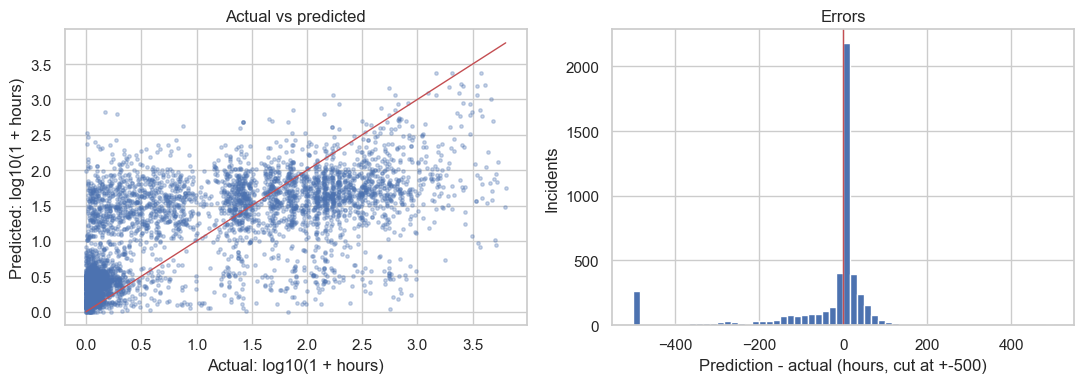

over-estimated: 64.4% | mean error: -89.1 | median error: 0.7


In [26]:
resid = pred - y
x, yp = np.log10(1 + y), np.log10(1 + pred)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x, yp, s=6, alpha=0.3, color="#4C72B0")
top_v = max(x.max(), yp.max())
axes[0].plot([0, top_v], [0, top_v], color="#C44E52", lw=1)    # perfect prediction
axes[0].set(xlabel="Actual: log10(1 + hours)", ylabel="Predicted: log10(1 + hours)", title="Actual vs predicted")
axes[1].hist(np.clip(resid, -500, 500), bins=60, color="#4C72B0", edgecolor="white")
axes[1].axvline(0, color="#C44E52", lw=1)
axes[1].set(xlabel="Prediction - actual (hours, cut at +-500)", ylabel="Incidents", title="Errors")
plt.tight_layout()
plt.show()
print("over-estimated:", f"{(resid > 0).mean():.1%}", "| mean error:", round(resid.mean(), 1), "| median error:", round(np.median(resid), 1))

Most short incidents are predicted correctly, while long incidents are often underestimated. Most errors are close to zero, but some very large negative errors remain. Overall, the model identifies fast incidents well but struggles to estimate the duration of slower ones.

In [27]:
def error_table(by):
    """Number of incidents, MAE of the baseline and of the model, and mean error, for each group."""
    d = pd.DataFrame({"by": by.reset_index(drop=True), "base": err_base, "model": err_model, "err": pred - y})
    out = d.groupby("by", observed=True).agg(n=("model", "size"), MAE_baseline=("base", "mean"),
                                             MAE_model=("model", "mean"), mean_error=("err", "mean")).round(1)
    out.index.name = by.name
    return out.reset_index()


duration = pd.cut(test[TARGET], [-0.1, 1, 24, np.inf], labels=["under 1 h", "1 to 24 h", "over 24 h"]).rename("real duration")
by_duration = error_table(duration)
display(by_duration)
display(error_table(test["priority"]))
error_table(test["category"]).sort_values("n", ascending=False).head(10)

,real duration,n,MAE_baseline,MAE_model,mean_error
0,under 1 h,2159,20.4,8.2,8.2
1,1 to 24 h,1027,13.1,31.8,29.6
2,over 24 h,1795,335.6,297.3,-273.9


,priority,n,MAE_baseline,MAE_model,mean_error
0,1 - Critical,35,138.3,140.2,-97.8
1,2 - High,61,84.3,91.4,-41.9
2,3 - Moderate,4764,135.0,119.3,-91.1
3,4 - Low,121,55.2,43.5,-30.2


,category,n,MAE_baseline,MAE_model,mean_error
26,Category 42,909,68.3,56.6,-45.6
14,Category 26,642,54.5,41.1,-34.0
30,Category 46,488,234.0,228.2,-155.7
36,Category 53,414,143.2,133.1,-108.6
18,Category 32,294,61.1,49.3,-46.0
39,Category 57,282,129.0,124.9,-99.1
22,Category 37,257,107.9,102.7,-80.1
45,Category 9,253,115.1,107.3,-67.5
11,Category 23,220,132.8,129.9,-103.5
8,Category 20,203,43.2,29.4,-25.2


**By duration:**
- Under 1 h: MAE 8.2 h (baseline: 20.4 h).
- 1–24 h: 31.8 h (baseline: 13.1 h).
- Over 24 h: 297.3 h (baseline: 335.6 h).

Long incidents represent 36% of the test set but account for 91% of the total error. They are the model's main weakness.

**By priority:** The model performs better for Moderate and Low incidents, but worse for Critical and High ones. These groups are small, so the results should be interpreted carefully.

**By category:** Category 46 has the highest MAE (228.2 h).

## 10. Model Interpretation

I use permutation importance on the test set. Each feature is shuffled to see how much the MAE increases. This shows which features are most useful to the model, but not what causes longer resolution times.

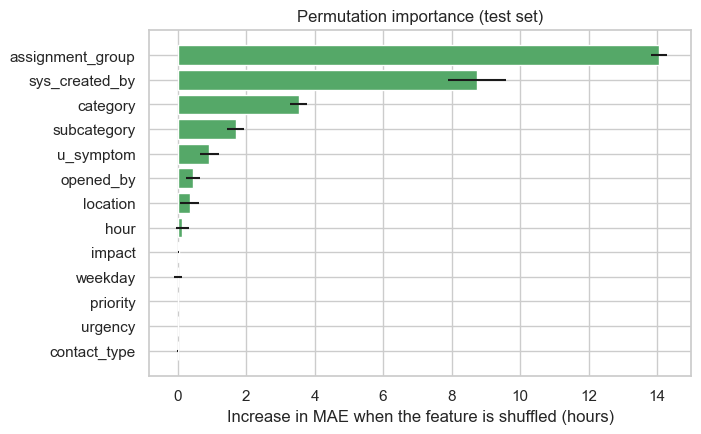

,increase in MAE (hours)
priority + impact + urgency,0.08
hour + weekday,0.20


In [28]:
imp = permutation_importance(final, test[FEATURES], test[TARGET], scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=RS, n_jobs=-1)
importance = pd.DataFrame({"mean": imp.importances_mean, "std": imp.importances_std}, index=FEATURES).sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance["mean"], xerr=importance["std"], color="#55A868")
ax.set(xlabel="Increase in MAE when the feature is shuffled (hours)", title="Permutation importance (test set)")
plt.show()


def shuffle_group(cols, repeats=5):
    """Increase in MAE when several columns are shuffled together (same new order for all of them)."""
    rng = np.random.default_rng(RS)
    reference = mean_absolute_error(y, final.predict(test[FEATURES]))
    scores = []
    for _ in range(repeats):
        X = test[FEATURES].copy()
        X[cols] = X[cols].iloc[rng.permutation(len(X))].to_numpy()
        scores.append(mean_absolute_error(y, final.predict(X)) - reference)
    return round(float(np.mean(scores)), 2)


pd.Series({"priority + impact + urgency": shuffle_group(["priority", "impact", "urgency"]),
           "hour + weekday": shuffle_group(["hour", "weekday"])}, name="increase in MAE (hours)").to_frame()

- `assignment_group` is the most important feature (+14.1 h), followed by `sys_created_by` (+8.7 h) and `category` (+3.5 h).
- Priority, impact and urgency have almost no effect (+0.08 h).
- The initial assignment group gives useful information about the type of incident. `sys_created_by` is also useful, but its missing values are difficult to explain.

These results show which features help the model, not what causes longer resolution times.

## 11. Limitations and Future Work

**Limitations:**
- **Long incidents:** The model improves MAE by 11.5%, but struggles with incidents over 24 h.
- **Limited data:** Most incidents come from February to May 2016, with changes over time.
- **Anonymised data:** Groups, users and categories cannot be clearly interpreted.
- **`sys_created_by`:** 46% of values are missing, and their impact is not fully understood.
- **Excluded incidents:** 13 unresolved incidents are not included.
- **Initial values:** The first event may not always reflect the exact opening state.
- **Small groups:** Critical and High results are based on very few incidents.
- **No causal analysis:** The results show relationships, not causes.

**Future work:**
- Predict resolution time ranges or classes (fast/slow).
- Improve predictions for long incidents.
- Test the model on data from other periods or companies.
- Add information collected during the first hours as a second prediction stage.

## 12. Conclusion

Using only information available when an incident is opened, the HistGradientBoosting model gets an MAE of **117.2 h**, compared with **132.5 h** for the median baseline. This is an improvement of 11.5% (95% interval: 12.8 to 18.0 h).

The model predicts short incidents quite well (MAE of 8.2 h for incidents under 1 h), but it struggles with long incidents. Incidents over 24 h account for about 91% of the total error.

Three main points came out of this work:

1. Some columns, such as `resolved_at`, `closed_at`, counters and the final assignment group, contain information only available after resolution. Using them would cause data leakage.
2. The log transformation of the target had a bigger impact than the choice of model. Ridge, Random Forest and boosting had validation MAE scores within 2 h of each other.
3. The model mainly relies on the initial assignment group and `sys_created_by`. Priority has very little impact.

Overall, the model can give a useful first estimate for planning, especially for identifying short incidents. However, its predictions for long incidents should be treated with caution.

## 13. References

- Dataset page: https://archive.ics.uci.edu/dataset/498/incident+management+process+enriched+event+log
- Tools: pandas, NumPy, scikit-learn (OneHotEncoder, TransformedTargetRegressor, HistGradientBoostingRegressor, RandomForestRegressor, Ridge, permutation_importance), matplotlib, seaborn.